Import Library

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

Import data

In [71]:
df = pd.read_csv("rumah123_yogya_unfiltered.csv")

In [72]:
df.head()

,price,nav-link,description,listing-location,bed,bath,carport,surface_area,building_area
0,"Rp 1,79 Miliar",https://www.rumah123.com/properti/sleman/hos17...,Rumah 2 Lantai Baru di jalan Palagan Sleman Y...,"Ngaglik, Sleman",3.0,3.0,2.0,120 m²,110 m²
1,Rp 170 Juta,https://www.rumah123.com/properti/sleman/hos17...,RUMAH BARU DEKAT AL AZHAR DAN UGM,"Jombor, Sleman",3.0,2.0,1.0,102 m²,126 m²
2,Rp 695 Juta,https://www.rumah123.com/properti/sleman/hos17...,RUMAH ASRI DAN SEJUK DI BERBAH SLEMAN DEKAT PA...,"Berbah, Sleman",2.0,2.0,1.0,100 m²,100 m²
3,Rp 560 Juta,https://www.rumah123.com/properti/sleman/hos17...,Rumah Murah 5 Menit Dari Candi Prambanan Tersi...,"Prambanan, Sleman",3.0,1.0,1.0,109 m²,67 m²
4,Rp 200 Juta,https://www.rumah123.com/properti/sleman/hos17...,Rumah Murah Cicilan 1jt Di Moyudan Sleman,"Moyudan, Sleman",2.0,1.0,1.0,60 m²,30 m²


In [73]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2020 entries, 0 to 2019
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   price             2020 non-null   str    
 1   nav-link          2020 non-null   str    
 2   description       2020 non-null   str    
 3   listing-location  2020 non-null   str    
 4   bed               2001 non-null   float64
 5   bath              1999 non-null   float64
 6   carport           1713 non-null   float64
 7   surface_area      2019 non-null   str    
 8   building_area     2019 non-null   str    
dtypes: float64(3), str(6)
memory usage: 142.2 KB


In [74]:
df.describe()

,bed,bath,carport
count,2001.000000,1999.000000,1713.000000
mean,3.969015,2.941971,1.559253
std,3.671654,3.517671,1.283030
min,1.000000,1.000000,1.000000
25%,2.000000,1.000000,1.000000
50%,3.000000,2.000000,1.000000
75%,4.000000,3.000000,2.000000
max,49.000000,49.000000,15.000000


In [75]:
df.isnull().sum()

price                 0
nav-link              0
description           0
listing-location      0
bed                  19
bath                 21
carport             307
surface_area          1
building_area         1
dtype: int64

In [76]:
def parse_price(s):
    s = str(s).replace("Rp", "").strip().lower()
    m = re.match(r"([\d\.,]+)\s*(miliar|juta|ribu)?", s)
    raw_num = m.group(1)
    n = float(raw_num.replace(",", ".")) if "," in raw_num else float(raw_num.replace(".", ""))
    return n * {"miliar": 1e9, "juta": 1e6, "ribu": 1e3, None: 1}[m.group(2)]

def parse_area(s):
    if pd.isna(s):
        return np.nan
    t = re.sub(r"[^\d,\.]", "", str(s))
    if not t:
        return np.nan
    return float(t.replace(".", "").replace(",", "."))


df_process = pd.DataFrame()

# 1) kolom teks: dibersihkan dan dipecah
df_process["listing_id"]      = df["nav-link"].str.extract(r"(hos\d+)")[0]
df_process["kategori_portal"] = df["nav-link"].str.extract(r"properti/([^/]+)/")[0]
df_process["deskripsi"]       = df["description"].str.replace(r"\s+", " ", regex=True).str.strip()

lokasi = df["listing-location"].str.replace(r"\s+", " ", regex=True).str.strip()
df_process["area"]      = lokasi.str.split(",").str[0].str.strip()
df_process["kab_label"] = lokasi.str.split(",").str[-1].str.strip()

# 2) harga: teks -> bilangan bulat (rupiah)
harga = df["price"].map(parse_price)
assert (harga - harga.round()).abs().max() < 1     # selisih hanya sisa hitungan desimal
df_process["harga"] = harga.round().astype("int64")

# 3) luas: teks -> bilangan bulat (m²), boleh kosong
df_process["luas_tanah"]    = df["surface_area"].map(parse_area).round().astype("Int64")
df_process["luas_bangunan"] = df["building_area"].map(parse_area).round().astype("Int64")
# df_process["harga_per_m2"] = df_process["harga"] / df_process["luas_tanah"] 
# 4) kamar dan carport: float -> bilangan bulat, boleh kosong
df_process["kamar_tidur"] = df["bed"].astype("Int64")
df_process["kamar_mandi"] = df["bath"].astype("Int64")
df_process["carport"]     = df["carport"].astype("Int64")




In [77]:
df_process.info()

<class 'pandas.DataFrame'>
RangeIndex: 2020 entries, 0 to 2019
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   listing_id       2020 non-null   str   
 1   kategori_portal  2020 non-null   str   
 2   deskripsi        2020 non-null   str   
 3   area             2020 non-null   object
 4   kab_label        2020 non-null   object
 5   harga            2020 non-null   int64 
 6   luas_tanah       2019 non-null   Int64 
 7   luas_bangunan    2019 non-null   Int64 
 8   kamar_tidur      2001 non-null   Int64 
 9   kamar_mandi      1999 non-null   Int64 
 10  carport          1713 non-null   Int64 
dtypes: Int64(5), int64(1), object(2), str(3)
memory usage: 183.6+ KB


In [78]:
df_process.describe().T

,count,mean,std,min,25%,50%,75%,max
harga,2020.0,1840271287.128713,2699890896.052423,7000000.0,645000000.0,1100000000.0,2132500000.0,42100000000.0
luas_tanah,2019.0,185.711243,250.696507,4.0,97.0,120.0,178.0,4222.0
luas_bangunan,2019.0,1192892.984646,53593898.399786,4.0,60.0,100.0,165.0,2408150000.0
kamar_tidur,2001.0,3.969015,3.671654,1.0,2.0,3.0,4.0,49.0
kamar_mandi,1999.0,2.941971,3.517671,1.0,1.0,2.0,3.0,49.0
carport,1713.0,1.559253,1.28303,1.0,1.0,1.0,2.0,15.0


In [79]:
df_process.isnull().sum()

listing_id           0
kategori_portal      0
deskripsi            0
area                 0
kab_label            0
harga                0
luas_tanah           1
luas_bangunan        1
kamar_tidur         19
kamar_mandi         21
carport            307
dtype: int64

In [80]:
df["listing_id"]  = df["nav-link"].str.extract(r"(hos\d+)")[0]
key = ["price", "description", "listing-location", "bed", "bath",
       "carport", "surface_area", "building_area"]          # 8 kolom, di luar URL

print("ID listing sama               :", df.duplicated("listing_id").sum())     
print("isi kolom sama selain URL     :", df.duplicated(key).sum())              
print("deskripsi sama                :", df.duplicated("description").sum())    

df["lokasi"] = df["listing-location"].str.replace(r"\s+", " ", regex=True).str.strip()
spec = ["harga",
    "area",
    "kab_label",
    "kamar_tidur",
    "kamar_mandi",
    "carport",
    "luas_tanah",
    "luas_bangunan"]
n_spec = df_process.duplicated(spec).sum()
print("harga+lokasi+spesifikasi sama :", n_spec, f"({n_spec/len(df)*100:.1f}%)")

ID listing sama               : 0
isi kolom sama selain URL     : 63
deskripsi sama                : 97
harga+lokasi+spesifikasi sama : 438 (21.7%)


In [81]:
# prasyarat: df_process sudah dibuat dari kode konversi tipe (termasuk kolom harga_per_m2)
d = df_process["deskripsi"].fillna("")

# --- pola teks untuk mendeteksi properti non-hunian ---
mulai = r"^\s*(?:dijual\s+|jual\s+)?(?:tanah|kavling|kapling|ruko|gudang|pabrik|kost|kos|hotel|villa|vila|homestay)\b"
kos   = (r"\b(?:kost|kos)\s*(?:putri|putra|eksklusif|ekslusif|exclusive|-?an|aktif|full|campur|[0-9]+ ?kamar)"
         r"|\b(?:rumah|bangunan)\s+(?:kost|kos)\b|\bkoskosan\b|\bkost\b")
lain  = r"\b(?:ruko|gudang|pabrik|homestay)\b"
tanah_saja = d.str.contains("tanah", case=False) & ~d.str.contains("rumah|rmh", case=False)

# --- flag per aturan (True = baris terkena aturan) ---
flag = pd.DataFrame(index=df_process.index)
flag["lb > 5000"]    = df_process["luas_bangunan"] > 5000
flag["luas tanah / bangunan<15"]    = (df_process["luas_tanah"] <= 15) | (df_process["luas_bangunan"] <= 15)
flag["Kamar tidur > 10"]     = df_process["kamar_tidur"] > 10
flag["Kamar mandi > 10"]    = df_process["kamar_mandi"] > 10
flag["Harga < Rp 50 juta"] = df_process["harga"] < 5e7
flag["Harga > Rp 20 miliar"]  = df_process["harga"] > 2e10
flag["Luas bangunan > 3 x luas tanah"]     = df_process["luas_bangunan"] > 3 * df_process["luas_tanah"]
flag["non_hunian"]    = (d.str.contains(mulai, case=False, regex=True)
                            | d.str.contains(kos,   case=False, regex=True)
                            | d.str.contains(lain,  case=False, regex=True)
                            | tanah_saja)
flag["Luas bangunan > luas tanah"]      = df_process["luas_bangunan"] > df_process["luas_tanah"]

# nilai kosong (<NA>) pada perbandingan dianggap "tidak terkena aturan"
flag = flag.fillna(False).astype(bool)

ringkasan = pd.DataFrame({"terdeteksi": flag.sum(),})
print(ringkasan)
print("LB > LT : ", round(flag["Luas bangunan > luas tanah"].mean() * 100, 1), "%")   # harapan: 24,5

                                terdeteksi
lb > 5000                                2
luas tanah / bangunan<15                 3
Kamar tidur > 10                        91
Kamar mandi > 10                        71
Harga < Rp 50 juta                       1
Harga > Rp 20 miliar                    10
Luas bangunan > 3 x luas tanah           9
non_hunian                             183
Luas bangunan > luas tanah             495
LB > LT :  24.5 %


Pemeriksaan format teks dan spasi ganda

In [82]:
# ============ 2.3.4 INKONSISTENSI FORMAT ============
# Ganti df_process dengan dataframe akhir (342 baris) bila sudah ada, mis. df_final
data = df_process.copy()

# --- (a) Harga & luas: format teks asli (sebelum parsing) ---
print("Satuan harga pada data mentah:")
print(df["price"].str.extract(r"(Miliar|Juta|Ribu)", flags=re.I)[0].str.title().value_counts(dropna=False))

print("\nHarga dengan pemisah desimal koma :", df["price"].str.contains(",").sum())
print("Contoh luas mentah               :", df["surface_area"].dropna().head(3).tolist())

# --- (b) Spasi ganda pada nama lokasi (data mentah) ---
spasi_ganda = df["listing-location"].str.contains(r"\s{2,}|^\s|\s$", regex=True)
print("\nLokasi bermasalah spasi (ganda/awal/akhir):", spasi_ganda.sum())
print(df.loc[spasi_ganda, "listing-location"].head(5).map(repr).to_string())

# setelah normalisasi (sudah dikerjakan di df_process)
print("\nSisa spasi ganda di df_process['area'] :",
      data["area"].str.contains(r"\s{2,}").sum())  

Satuan harga pada data mentah:
0
Miliar    1025
Juta       995
Name: count, dtype: int64

Harga dengan pemisah desimal koma : 930
Contoh luas mentah               : ['120 m²', '102 m²', '100 m²']

Lokasi bermasalah spasi (ganda/awal/akhir): 38
97           'Purwomartani   , Sleman'
205          'Purwomartani   , Sleman'
299    'Imogiri              , Bantul'
305          'Purwomartani   , Sleman'
412          'Purwomartani   , Sleman'

Sisa spasi ganda di df_process['area'] : 0


Kategori portal vs administratif

In [83]:
# --- (c) Kategori portal tidak sama dengan batas administratif ---
data["kategori_portal"] = data["kategori_portal"].str.strip().str.lower()
print("Distribusi kategori portal:")
print(data["kategori_portal"].value_counts())

yogya = data[data["kategori_portal"] == "yogyakarta"]
print(f"\nListing berkategori 'yogyakarta': {len(yogya)} dari {len(data)} "
      f"({len(yogya)/len(data)*100:.1f}%)")           # harapan: 150 dari 342 (43,9%)

print("\nArea di dalam kategori 'yogyakarta':")
print(yogya["area"].value_counts().to_string())

Distribusi kategori portal:
kategori_portal
sleman          1312
yogyakarta       342
bantul           321
kulon-progo       37
gunung-kidul       8
Name: count, dtype: int64

Listing berkategori 'yogyakarta': 342 dari 2020 (16.9%)

Area di dalam kategori 'yogyakarta':
area
Maguwoharjo      76
Umbulharjo       46
Sleman           37
Wirobrajan       27
Kotagede         18
Gondokusuman     16
Mantrijeron      16
Kraton           12
Tegalrejo         9
Jetis             9
Pogung            8
Bantul            8
Mergangsan        8
Kaliurang         7
Danurejan         7
Pakualaman        6
Seturan           6
Demangan          5
Gondomanan        5
Gedong Tengen     4
Caturtunggal      4
Nologaten         3
Cebongan          1
Imogiri           1
Kulonprogo        1
Purwomartani      1
Sekip             1


Koreksi kategori menjadi kabupaten/kota administratif

In [84]:
# --- (d) Pemetaan manual area -> kabupaten/kota administratif ---
peta_admin = {
    # Sleman
    "Maguwoharjo": "Sleman", "Sleman": "Sleman", "Kaliurang": "Sleman",
    "Pogung": "Sleman", "Seturan": "Sleman", "Caturtunggal": "Sleman",
    "Cebongan": "Sleman", "Purwomartani": "Sleman", "Nologaten" : "Sleman", "Sekip" : "Sleman",
    # Bantul
    "Bantul": "Bantul", "Imogiri": "Bantul",
    # Kulon Progo
    "Kulonprogo": "Kulon Progo",
}

# kategori portal lain diseragamkan ke penulisan administratif
norm_kategori = {
    "sleman": "Sleman", "bantul": "Bantul", "yogyakarta": "Kota Yogyakarta",
    "kulon-progo": "Kulon Progo", "kulon progo": "Kulon Progo", "kulonprogo": "Kulon Progo",
    "gunung-kidul": "Gunung Kidul", "gunungkidul": "Gunung Kidul",
}

data["kab_admin"] = data["kategori_portal"].map(norm_kategori).fillna(data["kategori_portal"].str.title())

# koreksi hanya untuk listing berkategori portal "yogyakarta"
mask = data["kategori_portal"].eq("yogyakarta")
data.loc[mask, "kab_admin"] = (
    data.loc[mask, "area"].map(peta_admin).fillna("Kota Yogyakarta")
)

# --- Tabel 10 ---
tabel10 = (
    data[mask]
    .groupby("kab_admin")
    .agg(Listing=("listing_id", "count"),
         Area_dipindahkan=("area", lambda s: ", ".join(sorted(set(s) & set(peta_admin)))))
    .reindex(["Kota Yogyakarta", "Sleman", "Bantul", "Kulon Progo"])
)
tabel10.loc["Kota Yogyakarta", "Area_dipindahkan"] = "—"
tabel10.index = ["Kota Yogyakarta (tetap)", "Sleman", "Bantul", "Kulon Progo"]
print("Tabel 10. Perubahan kategori wilayah 'Yogyakarta' setelah koreksi")
display(tabel10)   

print("Total:", tabel10["Listing"].sum(), "| dipindahkan:",
      (data.loc[mask, "kab_admin"] != "Kota Yogyakarta").sum())


Tabel 10. Perubahan kategori wilayah 'Yogyakarta' setelah koreksi


,Listing,Area_dipindahkan
Kota Yogyakarta (tetap),188,—
Sleman,144,"Caturtunggal, Cebongan, Kaliurang, Maguwoharjo..."
Bantul,9,"Bantul, Imogiri"
Kulon Progo,1,Kulonprogo


Total: 342 | dipindahkan: 154


Granularitas lokasi dan nama ambigu

In [85]:
# --- (e) Granularitas lokasi tidak seragam & nama ganda lintas kabupaten ---
print("Jumlah area unik          :", data["area"].nunique())

# nama area yang muncul di lebih dari satu kabupaten/kota (berdasar label portal & hasil koreksi)
lintas = (data.groupby("area")["kab_admin"].nunique().loc[lambda s: s > 1])
print("\nArea yang muncul di >1 kabupaten/kota:")
print(lintas.to_string() if len(lintas) else "tidak ada")

print("\nContoh: area 'Jetis'")
print(data[data["area"].eq("Jetis")].groupby(["kab_admin", "kab_label"]).size())

# contoh campuran tingkat kecamatan / kelurahan / kawasan
contoh = ["Maguwoharjo", "Seturan", "Pogung", "Condong Catur"]
print("\nContoh area bergranularitas berbeda:")
print(data[data["area"].isin(contoh)].groupby(["area", "kab_admin"]).size())

Jumlah area unik          : 60

Area yang muncul di >1 kabupaten/kota:
area
Jetis    2

Contoh: area 'Jetis'
kab_admin        kab_label 
Bantul           Bantul        17
Kota Yogyakarta  Yogyakarta     9
dtype: int64

Contoh area bergranularitas berbeda:
area           kab_admin
Condong Catur  Sleman       35
Maguwoharjo    Sleman       76
Pogung         Sleman        8
Seturan        Sleman        6
dtype: int64


Menyusun dataset analisis

In [86]:
# ============ 4. EDA ============
# Dataset analisis = data mentah dikurangi duplikat dan baris terkena aturan pengecualian.
# Aturan "Luas bangunan > luas tanah" TIDAK dibuang (24,5% data, rumah bertingkat itu wajar).
kolom_spek = ["harga", "lokasi", "kamar_tidur", "kamar_mandi", "carport", "luas_tanah", "luas_bangunan"]
df_process["lokasi"] = df["listing-location"].str.replace(r"\s+", " ", regex=True).str.strip()

# kab_admin dari Sel 3 sebelumnya; jika belum ada di df_process:
if "kab_admin" not in df_process:
    df_process["kab_admin"] = data["kab_admin"]

dup = df_process.duplicated(kolom_spek)
aturan_buang = [c for c in flag.columns if c != "Luas bangunan > luas tanah"]
terkena = flag[aturan_buang].any(axis=1)

eda = df_process[~dup & ~terkena].copy()
print(f"Data mentah        : {len(df_process)}")
print(f"Duplikat spesifikasi: {dup.sum()}")
print(f"Terkena aturan      : {terkena.sum()}")
print(f"Dataset analisis    : {len(eda)}")         
eda["harga_juta"] = eda["harga"] / 1e6
num = ["harga", "luas_tanah", "luas_bangunan", "kamar_tidur", "kamar_mandi", "carport"]

Data mentah        : 2020
Duplikat spesifikasi: 438
Terkena aturan      : 214
Dataset analisis    : 1386


Statistik deskriptif

In [87]:
ringkas = eda[num].describe(percentiles=[.25, .5, .75,]).T
ringkas["skewness"] = eda[num].skew()
display(ringkas.round(2))

print("Harga <= Rp 1 miliar :", f"{(eda.harga <= 1e9).mean()*100:.1f}%")
print("Harga <= Rp 2 miliar :", f"{(eda.harga <= 2e9).mean()*100:.1f}%")
print("Skewness harga       :", round(eda.harga.skew(), 2))
print("Luas tanah <= 200 m² :", f"{(eda.luas_tanah <= 200).mean()*100:.1f}%")

,count,mean,std,min,25%,50%,75%,max,skewness
harga,1386.0,1580075036.075036,1636355396.463494,69000000.0,645000000.0,990000000.0,1950000000.0,16000000000.0,3.42
luas_tanah,1385.0,169.182671,201.095387,36.0,97.0,120.0,165.0,4222.0,9.29
luas_bangunan,1385.0,128.837545,110.621276,23.0,60.0,100.0,156.0,1000.0,3.28
kamar_tidur,1371.0,3.22903,1.217298,1.0,2.0,3.0,4.0,10.0,1.53
kamar_mandi,1370.0,2.308759,1.23924,1.0,1.0,2.0,3.0,10.0,1.34
carport,1162.0,1.463855,1.042996,1.0,1.0,1.0,2.0,15.0,5.4


Harga <= Rp 1 miliar : 51.4%
Harga <= Rp 2 miliar : 77.4%
Skewness harga       : 3.42
Luas tanah <= 200 m² : 84.5%


Distribusi variabel utama

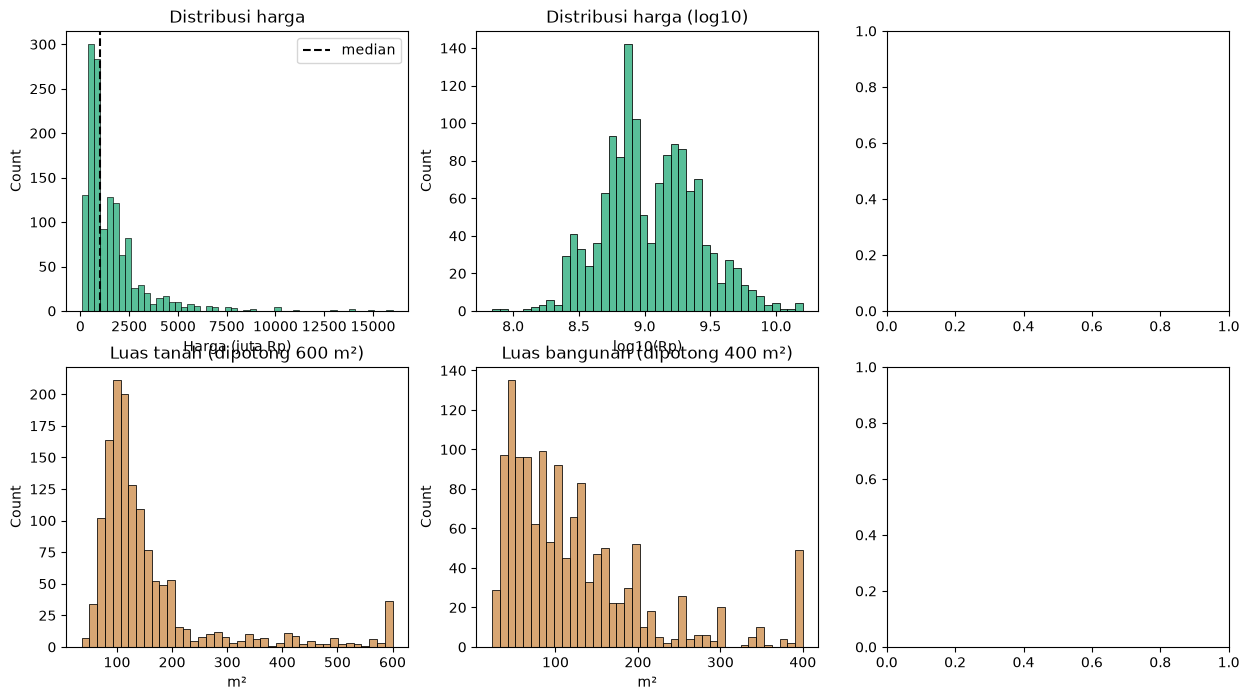

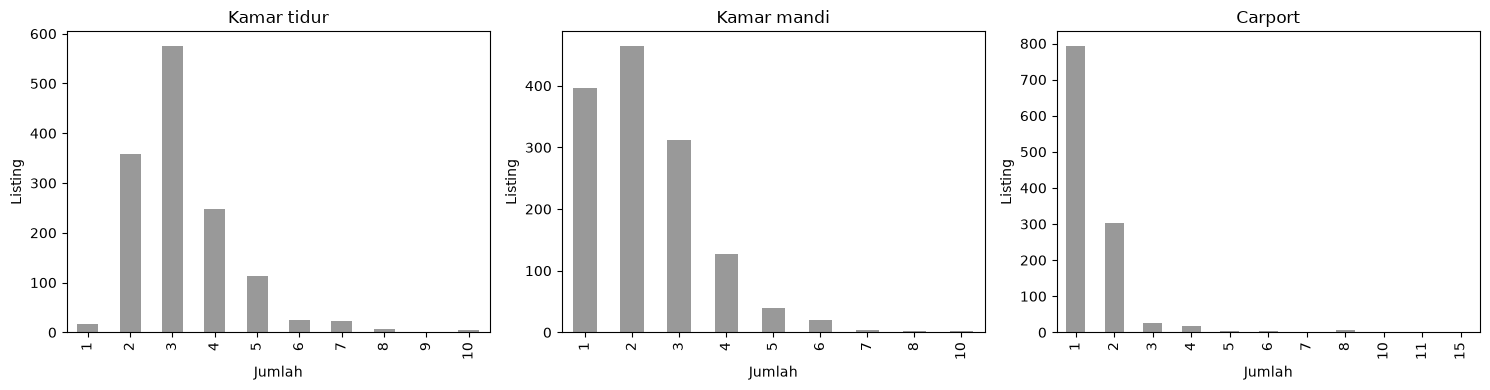

In [88]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))

sns.histplot(eda["harga_juta"], bins=50, ax=ax[0,0], color="#2a7")
ax[0,0].axvline(eda.harga_juta.median(), color="k", ls="--", label="median")
ax[0,0].set(title="Distribusi harga", xlabel="Harga (juta Rp)"); ax[0,0].legend()

sns.histplot(np.log10(eda["harga"]), bins=40, ax=ax[0,1], color="#2a7")
ax[0,1].set(title="Distribusi harga (log10)", xlabel="log10(Rp)")

# sns.histplot(eda["harga_per_m2"]/1e6, bins=40, ax=ax[0,2], color="#58a")
# ax[0,2].set(title="Harga per m² tanah", xlabel="Juta Rp/m²")

sns.histplot(eda["luas_tanah"].clip(upper=600), bins=40, ax=ax[1,0], color="#c84")
ax[1,0].set(title="Luas tanah (dipotong 600 m²)", xlabel="m²")

sns.histplot(eda["luas_bangunan"].clip(upper=400), bins=40, ax=ax[1,1], color="#c84")
ax[1,1].set(title="Luas bangunan (dipotong 400 m²)", xlabel="m²")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (kol, jdl) in zip(ax, [("kamar_tidur", "Kamar tidur"),
                              ("kamar_mandi", "Kamar mandi"),
                              ("carport", "Carport")]):
    eda[kol].value_counts().sort_index().plot.bar(ax=a, color="#999")
    a.set(title=jdl, xlabel="Jumlah", ylabel="Listing")

plt.tight_layout(); plt.show()

Korelasi antarvariabel

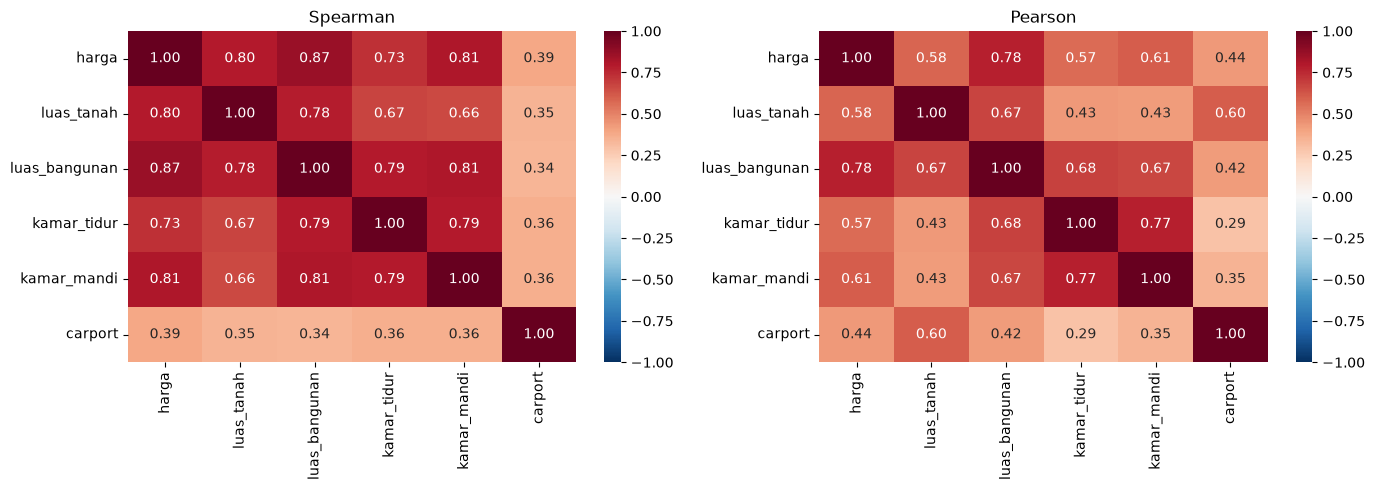

Korelasi dengan harga (Spearman):
luas_bangunan    0.87
kamar_mandi      0.81
luas_tanah       0.80
kamar_tidur      0.73
carport          0.39
Name: harga, dtype: float64


In [89]:
kor_var = ["harga", "luas_tanah", "luas_bangunan", "kamar_tidur", "kamar_mandi", "carport"]
sp = eda[kor_var].corr(method="spearman")
pe = eda[kor_var].corr(method="pearson")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(sp, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[0]); ax[0].set_title("Spearman")
sns.heatmap(pe, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[1]); ax[1].set_title("Pearson")
plt.tight_layout(); plt.show()

print("Korelasi dengan harga (Spearman):")
print(sp["harga"].drop("harga").sort_values(ascending=False).round(2))

Perbandingan antarwilayah dan jumlah kamar

,listing,median_harga,median_LT,median_LB,porsi_%
kab_admin,,,,,
Kota Yogyakarta,131,1.400000e+09,135.0,129.0,9.5
Sleman,1005,1.250000e+09,125.0,104.0,72.5
Bantul,217,6.650000e+08,97.0,60.0,15.7
Gunung Kidul,5,3.100000e+08,72.0,75.0,0.4
Kulon Progo,28,2.780000e+08,71.0,36.0,2.0


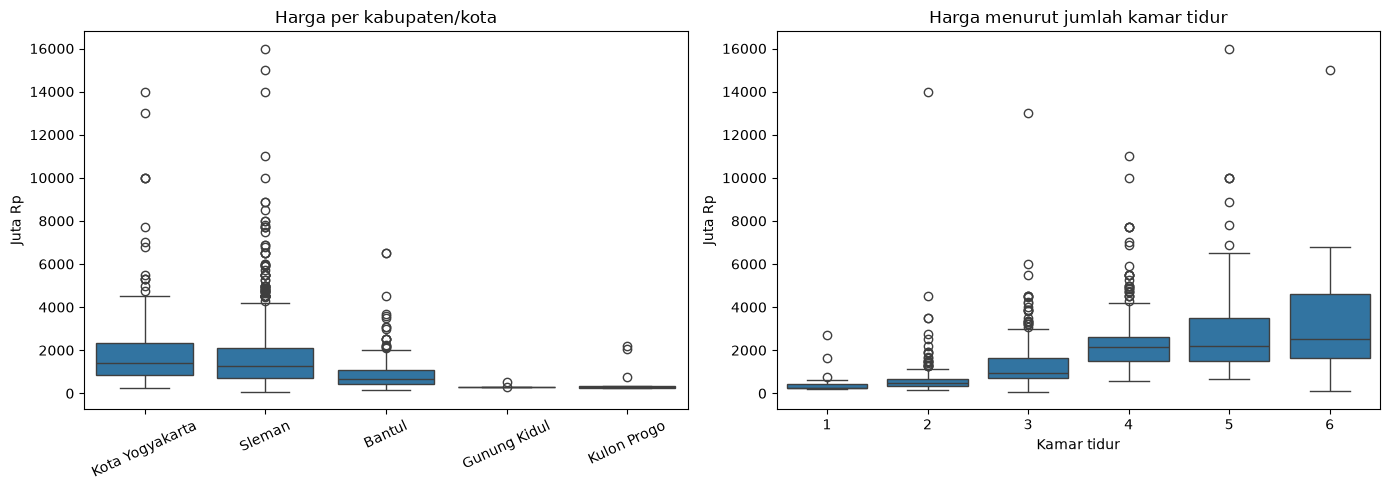

Listing LB > LT: 22.9%
Missing carport: 224


In [90]:
wil = (eda.groupby("kab_admin")
          .agg(listing=("harga", "size"),
               median_harga=("harga", "median"),
               median_LT=("luas_tanah", "median"),
               median_LB=("luas_bangunan", "median"),)
          .sort_values("median_harga", ascending=False))
wil["porsi_%"] = (wil.listing / wil.listing.sum() * 100).round(1)
display(wil)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
order = wil.index
sns.boxplot(data=eda, x="kab_admin", y="harga_juta", order=order, ax=ax[0], showfliers=True)
ax[0].set(title="Harga per kabupaten/kota", xlabel="", ylabel="Juta Rp")
ax[0].tick_params(axis="x", rotation=25)

sns.boxplot(data=eda[eda.kamar_tidur.between(1, 6)], x="kamar_tidur", y="harga_juta", ax=ax[1], showfliers=True)
ax[1].set(title="Harga menurut jumlah kamar tidur", xlabel="Kamar tidur", ylabel="Juta Rp")
plt.tight_layout(); plt.show()

print("Listing LB > LT:", f"{(eda.luas_bangunan > eda.luas_tanah).mean()*100:.1f}%")
print("Missing carport:", eda.carport.isna().sum())